# Experimento 4 · Análisis de sentimiento de las reseñas con BETO

> **Requiere GPU.** Pensado para Colab (T4 o mejor) u otro servidor con CUDA. En CPU funciona, pero tarda horas para las ~151 mil reseñas; usa `MUESTRA` para una prueba corta.

**Qué es BETO.** Un modelo BERT preentrenado desde cero con un corpus grande en español (Cañete et al., 2020, Universidad de Chile). Por sí solo no clasifica sentimiento: necesita una "cabeza" de clasificación afinada con ejemplos etiquetados. Este notebook ofrece dos caminos:

| `MODO` | Modelo | Ventaja | Costo |
|---|---|---|---|
| `'afinado'` (predeterminado) | `dccuchile/bert-base-spanish-wwm-cased` afinado aquí con **reseñas de Letterboxd de otros usuarios**, etiquetadas por sus estrellas | aprende el lenguaje de las reseñas de cine (no de tuits) | ~10 min de afinado + ~10 min de inferencia en T4 |
| `'preentrenado'` | `finiteautomata/beto-sentiment-analysis`: BETO afinado con tuits del corpus TASS 2020 (pysentimiento) | listo para usar, sin entrenamiento | ~10 min en T4 |

**Recomendación:** corre primero `'afinado'` (es el que alimenta a los experimentos) y, si hay tiempo, `'preentrenado'` como comparación. En una prueba con 300 reseñas, el modelo de tuits obtuvo F1-macro ≈ 0.40 y confundió trama oscura con opinión negativa ("Aquí es el pinche infierno…" con 5 ★): el lenguaje de una reseña de cine no es el de un tuit. Cada modo guarda sus propios archivos (`*_afinado`, `*_beto-sentiment-analysis`); el de la **última corrida completa** se copia además como `sentimiento_beto.parquet`, que es el que leen los notebooks 01–03.

En el modo afinado se usan solo reseñas de usuarios que **no** están en los experimentos, así que no hay fuga de información hacia la evaluación.

**Entrada:** `datos/limpios/resenas_sentimiento.parquet` (columna `texto_beto`: limpia, con emojis traducidos a palabras).
**Salida:** `datos/limpios/sentimiento/sentimiento_beto.parquet` con, por reseña, `p_neg`, `p_neu`, `p_pos`, la `etiqueta` y el puntaje `s = P(pos) − P(neg) ∈ [-1, 1]`.

Después de correrlo, copia ese archivo a la misma ruta en tu carpeta local y vuelve a ejecutar los notebooks 01, 02 y 03: detectarán el archivo y correrán la **variante B**.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os; os.environ['TT_RAIZ'] = '/content/drive/MyDrive/TT_Recomendador_Cine_Mexicano'

import os, sys, warnings
from pathlib import Path
RAIZ = Path(os.environ.get('TT_RAIZ', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
os.environ['TT_RAIZ'] = str(RAIZ)
sys.path.insert(0, str(RAIZ / 'src'))
warnings.filterwarnings('ignore', category=FutureWarning)
print('Raíz del proyecto:', RAIZ)

# En Colab, instala lo necesario (una sola vez por sesión):
# !pip install -q transformers pyarrow scikit-learn scipy matplotlib tqdm

Mounted at /content/drive
Raíz del proyecto: /content/drive/MyDrive/TT_Recomendador_Cine_Mexicano


In [2]:
!pip install -q transformers pyarrow scikit-learn scipy matplotlib tqdm

In [3]:
# --- Parámetros ----------------------------------------------------------------
MODO = 'afinado'                 # 'afinado' (recomendado) o 'preentrenado'
MODELO_PREENTRENADO = 'finiteautomata/beto-sentiment-analysis'
MODELO_BASE = 'dccuchile/bert-base-spanish-wwm-cased'

MAX_TOKENS = 256                 # cubre ~99 % de las reseñas (p95 ≈ 485 caracteres ≈ 120 tokens)
LOTE = 64                        # bájalo a 32 si la GPU se queda sin memoria
MUESTRA = None                   # p. ej. 2000 para probar; None = todas las reseñas
TAMANO_BLOQUE = 20_000           # se guarda avance cada bloque: si Colab se desconecta, retoma donde iba

# Solo para MODO = 'afinado'
N_POR_CLASE = 20_000             # reseñas por clase (negativo/neutral/positivo), balanceadas
EPOCAS = 2
TASA_APRENDIZAJE = 2e-5
LOTE_ENTRENAMIENTO = 32
MAX_TOKENS_AFINADO = 128
SEMILLA = 42

In [4]:
sys.path.append('/content/drive/MyDrive/TT_Recomendador_Cine_Mexicano/TT_Recomendador_Cine_Mexicano/src')

In [5]:
import json, math, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from recomendador import rutas, sentimiento as S

torch.manual_seed(SEMILLA)
DISPOSITIVO = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('Dispositivo:', DISPOSITIVO, '·', torch.cuda.get_device_name(0) if DISPOSITIVO == 'cuda' else '')
if DISPOSITIVO == 'cpu':
    print('⚠ Sin GPU: considera MUESTRA = 2000 para una prueba, y correr todo en Colab.')
SALIDA = rutas.carpeta_resultados('exp4')
rutas.SENTIMIENTO.mkdir(parents=True, exist_ok=True)

Dispositivo: cuda · Tesla T4


## 1. Datos de entrada

In [6]:
res = pd.read_parquet(rutas.LIMPIOS / 'resenas_sentimiento.parquet').sort_values('id').reset_index(drop=True)
if MUESTRA:
    res = res.sample(MUESTRA, random_state=SEMILLA).sort_values('id').reset_index(drop=True)
print(f'{len(res):,} reseñas  ·  por grupo: {res.grupo.value_counts().to_dict()}  ·  con estrellas: {res.calificacion.notna().mean():.1%}')
res[['grupo', 'calificacion', 'texto_beto']].sample(5, random_state=1)

151,516 reseñas  ·  por grupo: {'g5': 119872, 'g34': 31644}  ·  con estrellas: 96.3%


,grupo,calificacion,texto_beto
80010,g5,5.0,«ORA SI YA ME VOY PARA MI CASA» Luego de haber...
77598,g5,3.5,Aquí se inventaron las batallas de rap
677,g5,2.0,"tirada de maravilla, movimientos de camera que..."
143243,g5,4.0,"Ay, sí se me hizo bien linda Corinita, la verdad."
130442,g34,3.0,El hijo del burro


## 2. Funciones de inferencia

* Las reseñas se ordenan por longitud antes de agruparlas en lotes: así cada lote se rellena poco y la inferencia es varias veces más rápida.
* En GPU el modelo corre en media precisión (fp16).
* El orden de las clases se lee de la configuración del modelo (`id2label`), no se supone.

In [7]:
def indices_clase(id2label: dict) -> dict:
    """{'negativo': i, 'neutral': j, 'positivo': k} a partir de las etiquetas del modelo (NEG/NEU/POS, etc.)."""
    m = {}
    for i, etiqueta in id2label.items():
        e = str(etiqueta).upper()
        if e.startswith('NEG'): m['negativo'] = int(i)
        elif e.startswith('NEU'): m['neutral'] = int(i)
        elif e.startswith('POS'): m['positivo'] = int(i)
    if len(m) != 3:
        raise ValueError(f'El modelo no tiene 3 clases NEG/NEU/POS reconocibles: {id2label}')
    return m


def cargar_modelo(nombre):
    tok = AutoTokenizer.from_pretrained(nombre)
    mod = AutoModelForSequenceClassification.from_pretrained(nombre).to(DISPOSITIVO).eval()
    if DISPOSITIVO == 'cuda':
        mod = mod.half()
    return tok, mod, indices_clase(mod.config.id2label)


def predecir(textos, tok, mod, idx, max_tokens=MAX_TOKENS, lote=LOTE, barra=False):
    """Devuelve una matriz (n, 3) con P(negativo), P(neutral), P(positivo)."""
    orden = np.argsort([len(t) for t in textos])[::-1]   # los largos primero: si falta memoria, falla de inmediato
    probs = np.zeros((len(textos), 3), dtype=np.float32)
    columnas = [idx['negativo'], idx['neutral'], idx['positivo']]
    pasos = range(0, len(textos), lote)
    with torch.inference_mode():
        for i in (tqdm(pasos, leave=False) if barra else pasos):
            sel = orden[i:i + lote]
            enc = tok([textos[j] for j in sel], padding=True, truncation=True,
                      max_length=max_tokens, return_tensors='pt').to(DISPOSITIVO)
            logits = mod(**enc).logits.float()
            probs[sel] = torch.softmax(logits, dim=-1)[:, columnas].cpu().numpy()
    return probs

## 3. (Opcional) Afinado de BETO con reseñas de cine

Solo se ejecuta con `MODO = 'afinado'`. Las etiquetas salen de las estrellas (negativo ≤ 2 ★, neutral 2.5–3 ★, positivo ≥ 3.5 ★) y se balancean las clases. Se guarda el mejor modelo según F1-macro en una validación interna (10 %).

In [12]:
RUTA_AFINADO = rutas.RAIZ / 'modelos' / 'beto_afinado_resenas'

if MODO == 'afinado':
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import f1_score, classification_report

    ETQ = {'negativo': 0, 'neutral': 1, 'positivo': 2}
    afin = pd.read_parquet(rutas.LIMPIOS / 'resenas_afinado_beto.parquet')
    afin['clase'] = S.clase_desde_estrellas(afin.calificacion)
    afin = pd.concat([d.sample(min(len(d), N_POR_CLASE), random_state=SEMILLA) for _, d in afin.groupby('clase')])
    entrenamiento, validacion = train_test_split(afin, test_size=0.1, stratify=afin.clase, random_state=SEMILLA)
    print(f'Afinado: {len(entrenamiento):,} entrenamiento / {len(validacion):,} validación  ·  {afin.clase.value_counts().to_dict()}')

    tok = AutoTokenizer.from_pretrained(MODELO_BASE)
    mod = AutoModelForSequenceClassification.from_pretrained(
        MODELO_BASE, num_labels=3, id2label={0: 'NEG', 1: 'NEU', 2: 'POS'}, label2id={'NEG': 0, 'NEU': 1, 'POS': 2}
    ).to(DISPOSITIVO)

    usar_amp = DISPOSITIVO == 'cuda'
    try:
        escalador = torch.amp.GradScaler('cuda', enabled=usar_amp)
    except (AttributeError, TypeError):
        escalador = torch.cuda.amp.GradScaler(enabled=usar_amp)
    optimizador = torch.optim.AdamW(mod.parameters(), lr=TASA_APRENDIZAJE, weight_decay=0.01)
    pasos_totales = EPOCAS * math.ceil(len(entrenamiento) / LOTE_ENTRENAMIENTO)
    calentamiento = max(1, int(0.06 * pasos_totales))
    programa = torch.optim.lr_scheduler.LambdaLR(
        optimizador, lambda s: min((s + 1) / calentamiento, max(0.0, (pasos_totales - s) / max(1, pasos_totales - calentamiento))))

    textos, y = entrenamiento.texto_beto.tolist(), entrenamiento.clase.map(ETQ).values
    mejor_f1, historial = -1.0, []
    for epoca in range(EPOCAS):
        mod.train()
        perm = np.random.default_rng(SEMILLA + epoca).permutation(len(textos))
        perdidas = []
        for i in tqdm(range(0, len(perm), LOTE_ENTRENAMIENTO), desc=f'época {epoca + 1}/{EPOCAS}'):
            sel = perm[i:i + LOTE_ENTRENAMIENTO]
            enc = tok([textos[j] for j in sel], padding=True, truncation=True,
                      max_length=MAX_TOKENS_AFINADO, return_tensors='pt').to(DISPOSITIVO)
            etiquetas = torch.tensor(y[sel], device=DISPOSITIVO)
            contexto = torch.autocast(device_type='cuda', dtype=torch.float16) if usar_amp else contextlib.nullcontext()
            with contexto:
                perdida = mod(**enc, labels=etiquetas).loss
            optimizador.zero_grad(set_to_none=True)
            escalador.scale(perdida).backward()
            escalador.unscale_(optimizador)
            torch.nn.utils.clip_grad_norm_(mod.parameters(), 1.0)
            escalador.step(optimizador)
            escalador.update()
            programa.step()
            perdidas.append(perdida.item())
        mod.eval()
        p = predecir(validacion.texto_beto.tolist(), tok, mod, ETQ, max_tokens=MAX_TOKENS_AFINADO)
        f1 = f1_score(validacion.clase.map(ETQ), p.argmax(1), average='macro')
        historial.append({'epoca': epoca + 1, 'perdida_media': float(np.mean(perdidas)), 'f1_macro_val': f1})
        print(historial[-1])
        if f1 > mejor_f1:
            mejor_f1 = f1
            mod.save_pretrained(RUTA_AFINADO)
            tok.save_pretrained(RUTA_AFINADO)
    print(classification_report(validacion.clase.map(ETQ), p.argmax(1), target_names=list(ETQ)))
    pd.DataFrame(historial).to_csv(SALIDA / 'afinado_historial.csv', index=False)
    del mod
    if DISPOSITIVO == 'cuda':
        torch.cuda.empty_cache()
    MODELO_INFERENCIA = str(RUTA_AFINADO)
else:
    MODELO_INFERENCIA = MODELO_PREENTRENADO
print('Modelo para la inferencia:', MODELO_INFERENCIA)

Afinado: 54,000 entrenamiento / 6,000 validación  ·  {'negativo': 20000, 'neutral': 20000, 'positivo': 20000}


config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

... (9 outputs left out)

época 2/2:   0%|          | 0/1688 [00:00<?, ?it/s]

{'epoca': 2, 'perdida_media': 0.7310141504375856, 'f1_macro_val': 0.5954137396787327}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

              precision    recall  f1-score   support

    negativo       0.66      0.64      0.65      2000
     neutral       0.48      0.47      0.48      2000
    positivo       0.64      0.68      0.66      2000

    accuracy                           0.60      6000
   macro avg       0.60      0.60      0.60      6000
weighted avg       0.60      0.60      0.60      6000

Modelo para la inferencia: /content/drive/MyDrive/TT_Recomendador_Cine_Mexicano/modelos/beto_afinado_resenas


## 4. Inferencia sobre todas las reseñas (reanudable)

Cada bloque de 20 mil reseñas se guarda en `datos/limpios/sentimiento/parcial_beto_*`. Si la sesión se cae, al volver a correr esta celda se salta lo ya calculado. Si cambias `MODO` o `MUESTRA`, se usa otra carpeta de avance. **Si vuelves a afinar el modelo, borra antes la carpeta `parcial_beto_afinado_*`**: si no, se reutilizarían predicciones del modelo anterior.

In [13]:
tok, mod, idx = cargar_modelo(MODELO_INFERENCIA)
print('Clases del modelo:', mod.config.id2label, '→', idx)

etiqueta_modelo = MODO if MODO == 'afinado' else MODELO_PREENTRENADO.split('/')[-1]
PARCIAL = rutas.SENTIMIENTO / f"parcial_beto_{etiqueta_modelo}_{MUESTRA or 'todas'}"
PARCIAL.mkdir(parents=True, exist_ok=True)

inicios = list(range(0, len(res), TAMANO_BLOQUE))
for b, ini in enumerate(tqdm(inicios, desc='bloques')):
    ruta = PARCIAL / f'bloque_{b:03d}.parquet'
    if ruta.exists():
        continue
    parte = res.iloc[ini:ini + TAMANO_BLOQUE]
    p = predecir(parte.texto_beto.tolist(), tok, mod, idx, barra=True)
    pd.DataFrame({'id': parte.id.values, 'p_neg': p[:, 0], 'p_neu': p[:, 1], 'p_pos': p[:, 2]}).to_parquet(ruta, index=False)

probs = pd.concat([pd.read_parquet(r) for r in sorted(PARCIAL.glob('bloque_*.parquet'))], ignore_index=True)
assert len(probs) == len(res) and set(probs.id) == set(res.id), 'El avance guardado no corresponde a estas reseñas: borra la carpeta PARCIAL'

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Clases del modelo: {0: 'NEG', 1: 'NEU', 2: 'POS'} → {'negativo': 0, 'neutral': 1, 'positivo': 2}


bloques:   0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/180 [00:00<?, ?it/s]

In [14]:
salida = res[['id', 'usuario', 'item', 'grupo', 'calificacion']].merge(probs, on='id')
salida['etiqueta'] = np.array(S.CLASES)[salida[['p_neg', 'p_neu', 'p_pos']].values.argmax(1)]
salida['s'] = (salida.p_pos - salida.p_neg).clip(-1, 1)
salida['modelo'] = MODELO_INFERENCIA
salida = S.validar(salida)

# Cada modo deja su archivo; solo una corrida completa (sin MUESTRA) se copia como el oficial de los experimentos 1–3.
sufijo = f'{etiqueta_modelo}' + (f'_muestra_{MUESTRA}' if MUESTRA else '')
propio = rutas.SENTIMIENTO / f'sentimiento_beto_{sufijo}.parquet'
salida.to_parquet(propio, index=False)
print(f'Guardado: {propio}  ({len(salida):,} reseñas)')
if not MUESTRA:
    salida.to_parquet(rutas.ANALIZADORES['beto'], index=False)
    print(f'Copiado como archivo oficial para los experimentos: {rutas.ANALIZADORES["beto"]}')
salida.etiqueta.value_counts(normalize=True).rename('proporción').to_frame()

Guardado: /content/drive/MyDrive/TT_Recomendador_Cine_Mexicano/TT_Recomendador_Cine_Mexicano/datos/limpios/sentimiento/sentimiento_beto_afinado.parquet  (151,516 reseñas)
Copiado como archivo oficial para los experimentos: /content/drive/MyDrive/TT_Recomendador_Cine_Mexicano/TT_Recomendador_Cine_Mexicano/datos/limpios/sentimiento/sentimiento_beto.parquet


,proporción
etiqueta,
positivo,0.482952
neutral,0.301645
negativo,0.215403


## 5. Evaluación del analizador contra las estrellas

Las estrellas que el propio autor dio a la película sirven como referencia (ruidosa): negativo ≤ 2 ★, neutral 2.5–3 ★, positivo ≥ 3.5 ★. Se reportan exactitud, F1-macro, kappa de Cohen y la correlación de Spearman entre `s` y las estrellas.

,todas,g34,g5,largo <50,largo 50–150,largo 150–400,largo >400
resenas_evaluadas,145841,30532,115309,31733,53190,36461,24457
exactitud,0.629185,0.631993,0.628442,0.551949,0.605922,0.683717,0.698696
f1_macro,0.584158,0.57541,0.586178,0.518744,0.565355,0.635859,0.638741
kappa_cohen,0.387454,0.37371,0.390588,0.284634,0.360983,0.465233,0.468751
f1_negativo,0.564128,0.542078,0.569272,0.504386,0.547667,0.616783,0.626026
f1_neutral,0.438619,0.428835,0.441109,0.383219,0.422008,0.491645,0.474894
f1_positivo,0.749728,0.755316,0.748154,0.668628,0.726391,0.799148,0.815304
spearman_s_vs_estrellas,0.620086,0.595146,0.626244,0.503538,0.59002,0.700056,0.705306
mae_estrellas,0.75469,0.761634,0.752852,0.839753,0.784566,0.69128,0.67388


,pred_negativo,pred_neutral,pred_positivo
real_negativo,15575,6363,2271
real_neutral,8577,17561,9741
real_positivo,6857,20271,58625


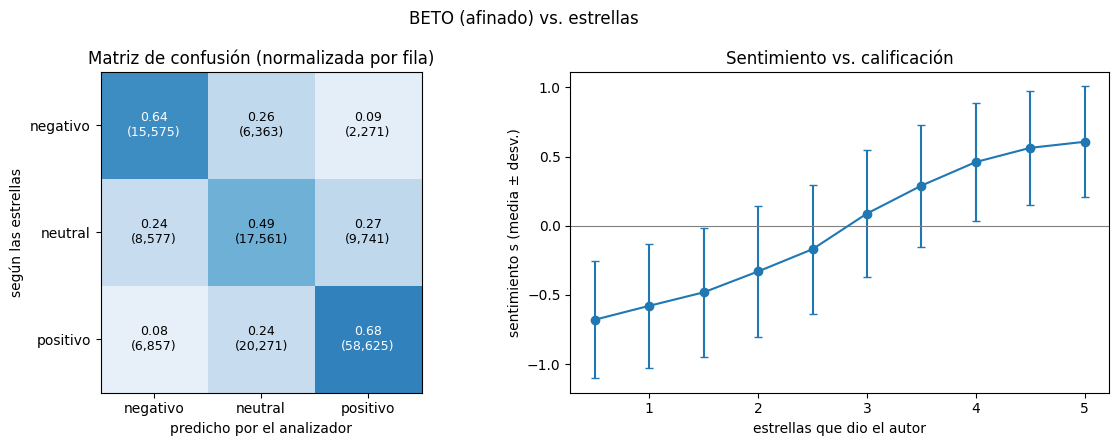

In [15]:
resumen, matriz = S.evaluar_contra_estrellas(salida)
por_grupo = {g: S.evaluar_contra_estrellas(d)[0] for g, d in salida.groupby('grupo')}
salida['largo'] = pd.cut(res.set_index('id').loc[salida.id, 'texto_beto'].str.len().values,
                         [0, 50, 150, 400, 10**6], labels=['<50', '50–150', '150–400', '>400'])
por_largo = {str(l): S.evaluar_contra_estrellas(d)[0] for l, d in salida.groupby('largo', observed=True)}

tabla = pd.DataFrame({'todas': resumen, **por_grupo, **{f'largo {k}': v for k, v in por_largo.items()}})
claves = ['resenas_evaluadas', 'exactitud', 'f1_macro', 'kappa_cohen', 'f1_negativo', 'f1_neutral', 'f1_positivo',
          'spearman_s_vs_estrellas', 'mae_estrellas']
display(tabla.loc[claves])
display(matriz)

tabla.to_csv(SALIDA / f'metricas_sentimiento_beto_{sufijo}.csv')
matriz.to_csv(SALIDA / f'matriz_confusion_beto_{sufijo}.csv')
metricas = {'modelo': MODELO_INFERENCIA, 'modo': MODO, 'muestra': MUESTRA, **resumen}
for nombre in [f'metricas_sentimiento_beto_{sufijo}.json'] + ([] if MUESTRA else ['metricas_sentimiento_beto.json']):
    with open(SALIDA / nombre, 'w') as f:
        json.dump(metricas, f, indent=2, default=float, ensure_ascii=False)
S.graficar_evaluacion(salida, matriz, f'BETO ({etiqueta_modelo}) vs. estrellas', SALIDA / f'evaluacion_beto_{sufijo}.png');

## 6. Análisis de errores

Desacuerdos fuertes entre el texto y las estrellas. Muchos no son errores del modelo: reseñas irónicas, comentarios sobre otra cosa ("vine por Gael"), o estrellas que no reflejan el texto.

In [16]:
textos = res.set_index('id')['texto_beto']
alto_negativo = salida[(salida.calificacion >= 4.5) & (salida.etiqueta == 'negativo')].nsmallest(6, 's')
bajo_positivo = salida[(salida.calificacion <= 1.0) & (salida.etiqueta == 'positivo')].nlargest(6, 's')
for titulo, d in [('★★★★½+ pero BETO dice negativo', alto_negativo), ('★ o menos pero BETO dice positivo', bajo_positivo)]:
    print('\n' + titulo)
    display(d.assign(texto=textos.loc[d.id].values)[['calificacion', 's', 'texto']])


★★★★½+ pero BETO dice negativo


,calificacion,s,texto
33783,5.0,-0.986768,le dediqué la tesis a esta mierda
46117,5.0,-0.983189,"Cantidad, ni siquiera adecuada, PERFECTA de ve..."
17874,5.0,-0.983173,Es la peor versión de Hotel California que he ...
119554,4.5,-0.979201,Chingonería de película. La directora de fotog...
8791,5.0,-0.976030,La comedia más aburrida que he visto
114974,4.5,-0.974586,Este caso (como muchos más) es prueba de lo en...



★ o menos pero BETO dice positivo


,calificacion,s,texto
19918,0.5,0.952447,La mejor película de todas
19339,0.5,0.948334,estoy viendo todas las grandes películas de 20...
19604,1.0,0.946535,Martirio Goicochea dejó la estación a las 19:4...
46741,1.0,0.939953,Ya avía visto esta película pero la volví a ve...
40002,0.5,0.937875,"Obra incomprendida del cine moderno Dios, la s..."
105139,0.5,0.937605,el verdadero cine de oro mexicano me encanta


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 7. Siguiente paso

1. Descarga `datos/limpios/sentimiento/sentimiento_beto.parquet` (y `resultados/exp4/`) a tu carpeta local, en la misma ruta.
2. Vuelve a ejecutar `01`, `02` y `03`: correrán la **variante B** automáticamente.
3. Ejecuta `06_comparacion_resultados.ipynb` para el cuadro final.